[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/03-math-for-ai/notebooks/03-probability-and-softmax.ipynb)

# 03 · Probability, distributions, mean/variance and softmax

**What you will learn**
- probability as a number from 0 to 1, and simulation with NumPy
- the **law of large numbers**
- uniform, normal and binomial **distributions**
- **mean**, **variance** and **standard deviation**, by hand and with NumPy
- **softmax** (scores → probabilities) and **temperature**
- sampling a "next word" like a language model, and **cross-entropy**

## 0. Setup

`default_rng(42)` makes our random numbers repeatable (the 42 is a **seed**).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)   # print numbers neatly
NAVY, TEAL, RED, ORANGE = "#1B263B", "#0F9D9A", "#D1495B", "#F28C28"   # course colours
rng = np.random.default_rng(42)

## 1. Simulating a coin

`rng.random(n)` gives n numbers between 0 and 1. "Heads" = number below 0.5. With 10 flips the share of heads can be far from 0.5.

In [2]:
flips = rng.random(10) < 0.5
print(flips.astype(int))
print("share of heads:", flips.mean())

[0 1 0 0 1 0 0 0 1 1]
share of heads: 0.4


## 2. The law of large numbers

Keep flipping and track the running share of heads. It wobbles at first, then settles near 0.5.

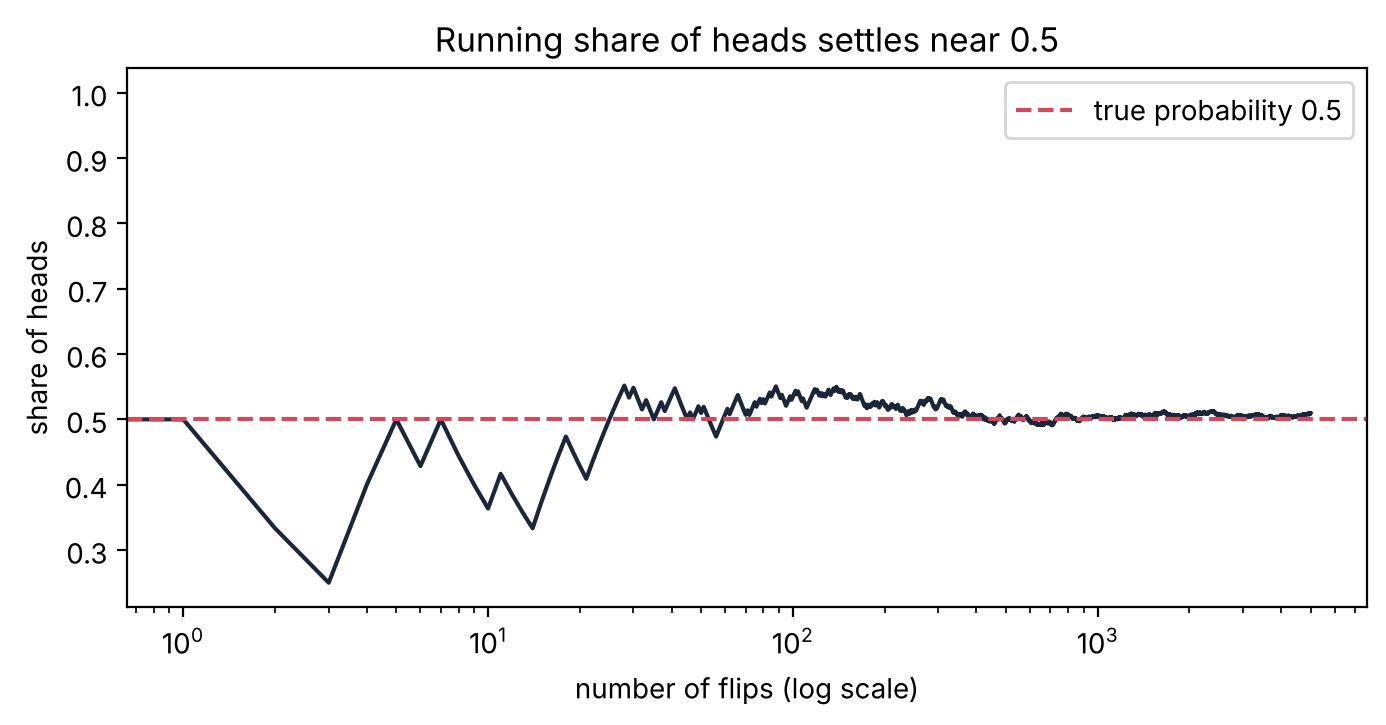

after 5000 flips: 0.5092


In [3]:
n = 5000
flips = rng.random(n) < 0.5
running = np.cumsum(flips) / np.arange(1, n + 1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(running, color=NAVY)
ax.axhline(0.5, color=RED, ls="--", label="true probability 0.5")
ax.set_xscale("log"); ax.set_xlabel("number of flips (log scale)"); ax.set_ylabel("share of heads")
ax.set_title("Running share of heads settles near 0.5"); ax.legend(); plt.show()
print("after", n, "flips:", running[-1])

## 3. Three distributions

- **uniform**: every value equally likely (a die)
- **normal**: bell curve around a mean (heights)
- **binomial**: number of successes in a fixed number of yes/no tries (heads in 10 flips)

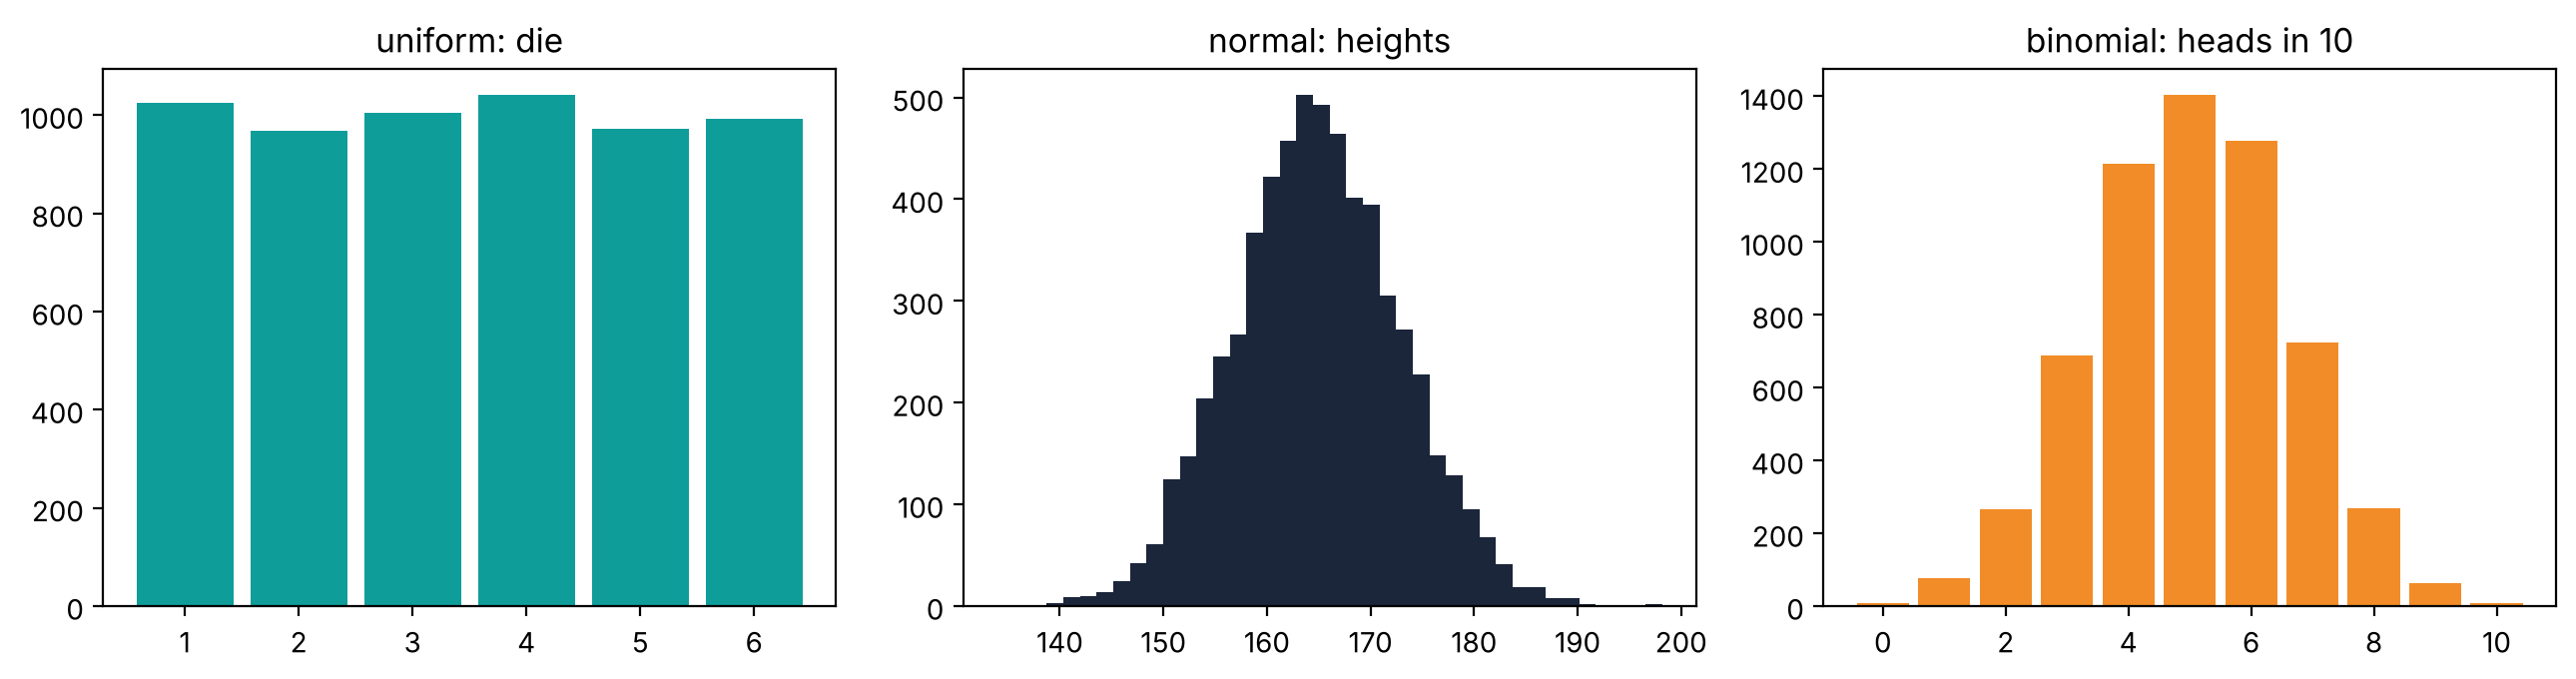

In [4]:
die = rng.integers(1, 7, 6000)
heights = rng.normal(loc=165, scale=8, size=6000)
heads = rng.binomial(n=10, p=0.5, size=6000)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(die, bins=np.arange(0.5, 7.5), rwidth=0.85, color=TEAL); axes[0].set_title("uniform: die")
axes[1].hist(heights, bins=40, color=NAVY); axes[1].set_title("normal: heights")
axes[2].hist(heads, bins=np.arange(-0.5, 11.5), rwidth=0.85, color=ORANGE); axes[2].set_title("binomial: heads in 10")
plt.tight_layout(); plt.show()

## 4. Mean, variance and standard deviation by hand

- mean = sum ÷ count
- variance = average of squared distances from the mean
- standard deviation = square root of variance (same units as the data)

In [5]:
data = np.array([4, 8, 6, 5, 7])
mean = data.sum() / len(data)
deviations = data - mean
variance = (deviations ** 2).mean()
std = np.sqrt(variance)
print("deviations:", deviations)
print(f"mean={mean}, variance={variance}, std={std:.3f}")
print("numpy agrees:", data.mean(), data.var(), round(data.std(), 3))

deviations: [-2.  2.  0. -1.  1.]
mean=6.0, variance=2.0, std=1.414
numpy agrees: 6.0 2.0 1.414


Note: NumPy's `var()`/`std()` divide by n (the "population" version). pandas' `.var()`/`.std()` divide by n − 1 (the "sample" version) by default, so the numbers differ slightly on small data. Neither is wrong; just know which one you used.

## 5. Same mean, different spread

Two archers both average the bullseye (0), but one is much more scattered.

tight: mean=0.04 std=1.01
loose: mean=0.06 std=2.89


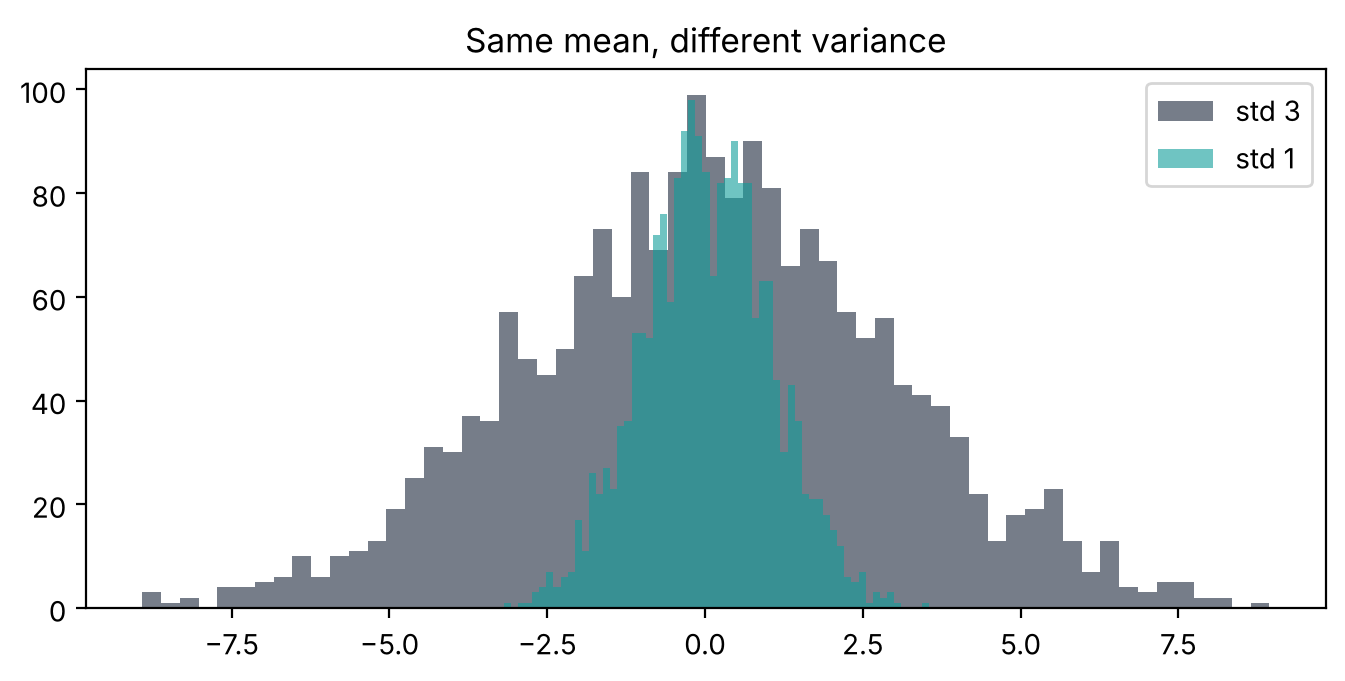

share of heights within 1 std of the mean: 67.7% (about 68% for a normal distribution)


In [6]:
tight = rng.normal(0, 1, 2000)
loose = rng.normal(0, 3, 2000)
print(f"tight: mean={tight.mean():.2f} std={tight.std():.2f}")
print(f"loose: mean={loose.mean():.2f} std={loose.std():.2f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(loose, bins=60, alpha=0.6, color=NAVY, label="std 3")
ax.hist(tight, bins=60, alpha=0.6, color=TEAL, label="std 1")
ax.set_title("Same mean, different variance"); ax.legend(); plt.show()
within1 = np.mean(np.abs(heights - heights.mean()) < heights.std())
print(f"share of heights within 1 std of the mean: {within1:.1%} (about 68% for a normal distribution)")

## 6. Softmax: scores to probabilities

Two steps: `exp` every score (all positive, bigger gaps), then divide by the total (sums to 1).
We subtract the largest score first: it does not change the answer but stops `exp` from overflowing on big numbers. This is called the **numerically stable** version.

In [7]:
def softmax(scores, temperature=1.0):
    z = np.asarray(scores, dtype=float) / temperature
    z = z - z.max()                 # stability trick, result unchanged
    e = np.exp(z)
    return e / e.sum()

logits = np.array([2.0, 1.0, 0.1])
print("exp:     ", np.exp(logits))
print("softmax: ", softmax(logits))
print("sum:     ", softmax(logits).sum())
print("big scores still fine:", softmax([1000, 999, 998]))

exp:      [7.389 2.718 1.105]
softmax:  [0.659 0.242 0.099]
sum:      1.0
big scores still fine: [0.665 0.245 0.09 ]


## 7. Temperature

Divide scores by the temperature before softmax. Low → sharp (predictable). High → flat (varied). This is the `temperature` setting of LLM APIs (Module 07).

T=0.5: {'cat': np.float64(0.815), 'dog': np.float64(0.165), 'car': np.float64(0.015), 'tree': np.float64(0.004), 'sky': np.float64(0.001)}
T=1.0: {'cat': np.float64(0.592), 'dog': np.float64(0.266), 'car': np.float64(0.08), 'tree': np.float64(0.044), 'sky': np.float64(0.018)}
T=2.0: {'cat': np.float64(0.402), 'dog': np.float64(0.27), 'car': np.float64(0.148), 'tree': np.float64(0.11), 'sky': np.float64(0.07)}


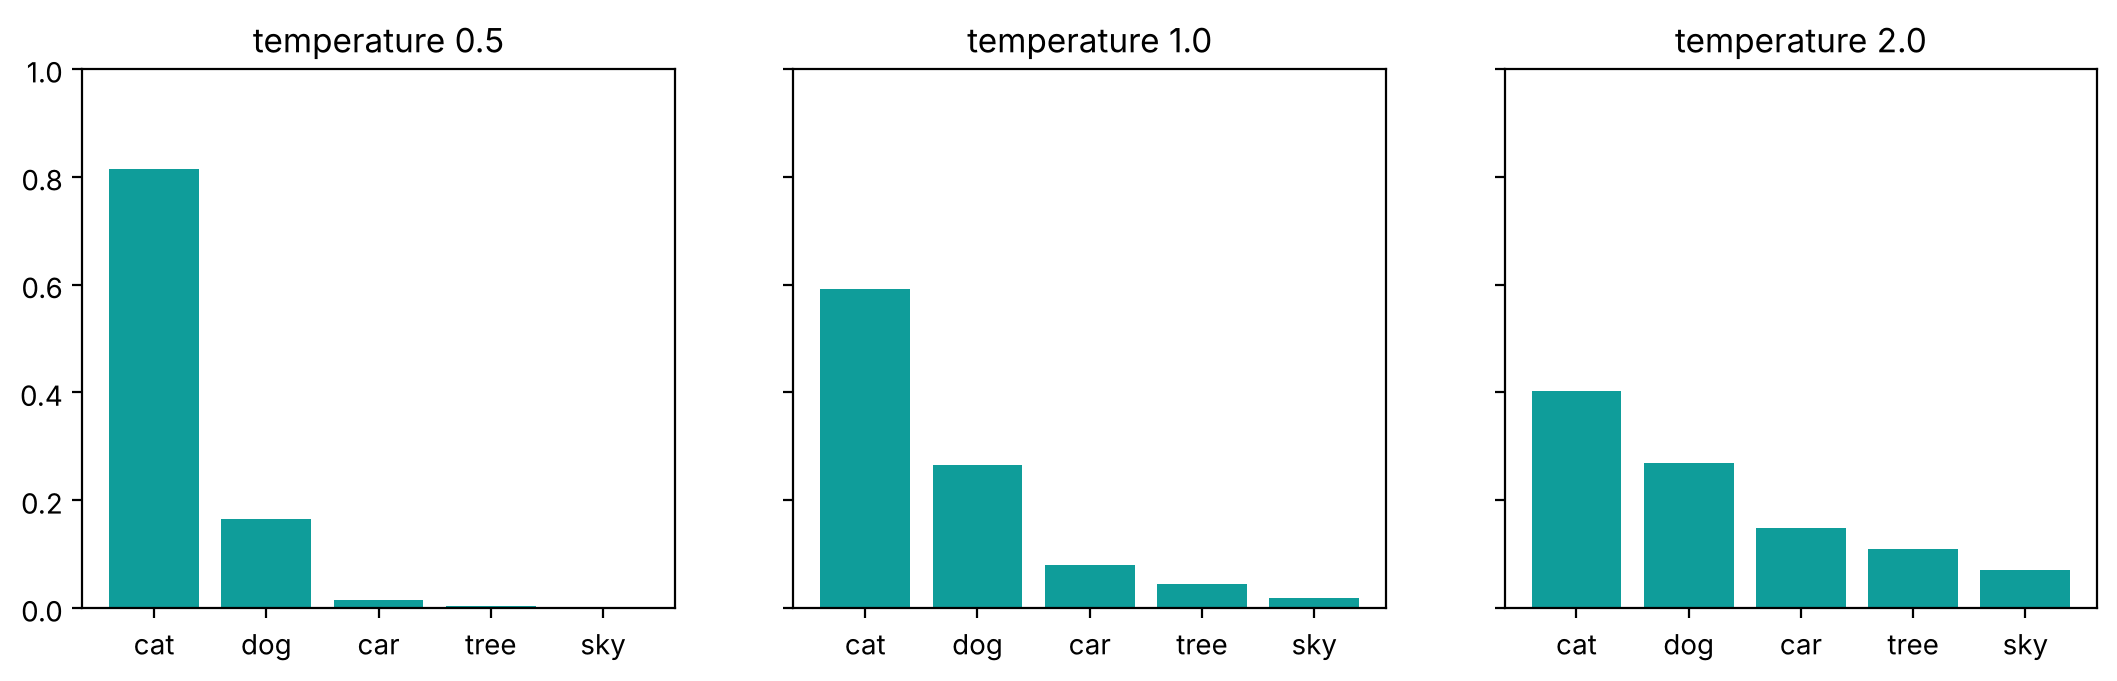

In [8]:
vocab = ["cat", "dog", "car", "tree", "sky"]
logits = np.array([3.0, 2.2, 1.0, 0.4, -0.5])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, t in zip(axes, [0.5, 1.0, 2.0]):
    p = softmax(logits, t)
    ax.bar(vocab, p, color=TEAL); ax.set_title(f"temperature {t}"); ax.set_ylim(0, 1)
    print(f"T={t}:", dict(zip(vocab, p.round(3))))
plt.show()

## 8. Sampling the "next word"

A language model turns logits into probabilities with softmax, then **samples** (picks at random, weighted by probability). `rng.choice(..., p=probs)` does that. Count what we get from 1000 picks at two temperatures.

In [9]:
for t in [0.5, 2.0]:
    probs = softmax(logits, t)
    picks = rng.choice(vocab, size=1000, p=probs)
    words, counts = np.unique(picks, return_counts=True)
    print(f"T={t}:", dict(zip(words, counts)))

T=0.5: {np.str_('car'): np.int64(14), np.str_('cat'): np.int64(820), np.str_('dog'): np.int64(162), np.str_('sky'): np.int64(1), np.str_('tree'): np.int64(3)}
T=2.0: {np.str_('car'): np.int64(167), np.str_('cat'): np.int64(404), np.str_('dog'): np.int64(244), np.str_('sky'): np.int64(78), np.str_('tree'): np.int64(107)}


## 9. Cross-entropy: how wrong was the prediction?

Cross-entropy loss = −log(probability the model gave to the **correct** answer). Confident and right → small loss. Confident and wrong → big loss.

In [10]:
probs = softmax(logits)
for correct in ["cat", "car", "sky"]:
    p = probs[vocab.index(correct)]
    print(f"correct word '{correct}': p = {p:.3f}, loss = {-np.log(p):.3f}")

correct word 'cat': p = 0.592, loss = 0.524
correct word 'car': p = 0.080, loss = 2.524
correct word 'sky': p = 0.018, loss = 4.024


## Your turn
1. Roll two dice 10,000 times and plot a histogram of their **sum**. Which total is most common? (Hint: `rng.integers(1, 7, (10000, 2)).sum(axis=1)`.)
2. Find the temperature at which "cat" gets at least 90 % probability.

## Recap
Probabilities are 0..1 and sum to 1. Distributions describe how likely each value is. Mean = centre, variance/std = spread. Softmax turns scores into probabilities; temperature sharpens or flattens them; cross-entropy scores a prediction.